# 05 — Machine learning on the curves: anomaly detection and classification

**What this notebook does**

1. **Anomaly detection with known truth.** The real curves are all «good» (pre-selected), so there is no sample of real defects on which to measure the efficiency. We therefore generate **synthetic** Hertz-like curves, with parameters sampled from the real curves, inject 5 types of instrumental defect (`no_contact`, `saturation`, `huge_noise`, `jump`, `wrong_slope`), and evaluate anomaly detectors (Isolation Forest, robust Mahalanobis distance), unsupervised;
2. applies the detector, trained on the real curves, to the real curves and flags the most anomalous ones (for manual inspection: **none is discarded**);
3. **classification** of the region (cytoplasm vs nucleus) from mechanical and adhesion features, per line, with cross-validation, permutation test, calibration, feature importance and **transfer between lines**;
4. checks with **Gaussian mixture** models the bimodality of $\log A$ suggested by the posterior predictive check of notebook 04.

**What it does NOT do**

- it does not exclude curves from the statistics of notebooks 03–04: anomaly detection is diagnostic;
- the efficiency estimated on synthetic data holds for *these* defects and *this* curve model: it is a realistic upper bound, not a guarantee on real defects;
- it does not redo the fits of the real curves (it reads `results/` from notebook 02); the synthetic fits use the same functions of `afm_tools.py`.

Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.ensemble import IsolationForest, RandomForestClassifier, GradientBoostingClassifier
from sklearn.covariance import MinCovDet
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.mixture import GaussianMixture
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED)
real = T.load_fit_table(); real = real[real.fit_status == "ok"].copy()
real["rel_err_A"] = real.A_err_nN_per_um_3over2 / real.A_nN_per_um_3over2
summary = {}
print(len(real), "real curves")

257 real curves


## 1. Synthetic curves with injected defects

For each synthetic curve a real curve is sampled as «template» (A, noise, baseline slope, maximum force) and $F=A\,\delta^{3/2}+\text{baseline}+\text{noise}$ is generated with 5000 points, ending at the setpoint force like the real curves; a slow correlated multiplicative model mismatch is added (real curves are not pure Hertz). 5% of the curves receive a defect:

| defect | effect |
|---|---|
| `no_contact` | $A\to$ negligible: only baseline and noise |
| `saturation` | force clipped at 40–60% of the maximum (photodiode saturation) |
| `huge_noise` | noise ×8–20 |
| `jump` | sudden force jump (0.2–0.5 $F_{max}$) at a random point of the contact |
| `wrong_slope` | exponent different from 3/2 (0.7 or 2.6): non-Hertzian contact |

In [2]:
DEFECTS = ["no_contact", "saturation", "huge_noise", "jump", "wrong_slope"]

def synth_curve(src, defect, rg, n=5000, misfit=0.06):
    A, noise, slope, fmax = src.A_nN_per_um_3over2, src.baseline_noise_pN / 1e3, src.baseline_slope_nN_per_um, src.fmax_nN
    dmax = (fmax / A) ** (2 / 3)                              # indentation at the setpoint: the real curve ends here
    z0, zr = -9.4, 6.0
    zc = z0 - rg.uniform(.55, .85) * zr
    zc = max(zc, z0 - zr + dmax + 0.05)
    z = np.linspace(z0, zc - dmax, n)                         # z decreases along the extend (as in the real data)
    p, noise_eff = 1.5, noise
    if defect == "wrong_slope": p = rg.choice([0.7, 2.6])
    if defect == "huge_noise": noise_eff = noise * rg.uniform(8, 20)
    d = np.clip(zc - z, 0, None)
    # correlated model mismatch (the real curve is not a pure Hertz): slow multiplicative factor
    eps = gaussian_filter1d(rg.standard_normal(n), sigma=0.02 * n); eps /= eps.std()
    F = (A * d ** p if defect != "wrong_slope" else fmax * (d / max(d.max(), 1e-9)) ** p) * (1 + misfit * eps)
    if defect == "no_contact": F = 0.01 * F
    F = F + slope * (z - z0) + noise_eff * rg.standard_normal(n)
    if defect == "jump":
        i = rg.integers(int(n * .8), int(n * .97)); F[i:] += rg.choice([-1, 1]) * rg.uniform(.2, .5) * fmax
    if defect == "saturation": F = np.minimum(F, rg.uniform(.4, .6) * fmax)
    return z, F

def features_from_fit(r):
    keys = ["fit_r2", "fit_rmse_rel", "snr", "n_fit_points", "max_indentation_um", "baseline_noise_pN", "baseline_slope_nN_per_um",
            "jump_score", "sat_fraction", "contact_shift_rel", "exponent_hat", "fmax_nN"]
    out = {k: r.get(k, np.nan) for k in keys}
    out["logA"] = np.log(r["A_nN_per_um_3over2"]) if r.get("A_nN_per_um_3over2", 0) > 0 else np.nan
    out["rel_err_A"] = r.get("A_err_nN_per_um_3over2", np.nan) / r.get("A_nN_per_um_3over2", np.nan)
    return out

FEATS = ["fit_r2", "fit_rmse_rel", "snr", "n_fit_points", "max_indentation_um", "baseline_noise_pN", "baseline_slope_nN_per_um",
         "jump_score", "sat_fraction", "contact_shift_rel", "exponent_hat", "logA", "rel_err_A"]
N_SYN, FRAC_BAD = 1000, 0.05
rg = np.random.default_rng(SEED); rows = []
labels = np.array(["ok"] * N_SYN, dtype=object); bad_idx = rg.choice(N_SYN, int(FRAC_BAD * N_SYN), replace=False)
labels[bad_idx] = np.resize(DEFECTS, len(bad_idx))
for i in range(N_SYN):
    z, F = synth_curve(real.iloc[rg.integers(len(real))], labels[i] if labels[i] != "ok" else None, rg)
    r = T.fit_curve(z, F)
    row = features_from_fit(r) if r["fit_status"] == "ok" else {k: np.nan for k in FEATS}
    row.update(defect=labels[i], failed=r["fit_status"] != "ok"); rows.append(row)
syn = pd.DataFrame(rows)
print(syn.defect.value_counts().to_dict(), "| failed fits:", int(syn.failed.sum()), syn[syn.failed].defect.value_counts().to_dict())

{'ok': 950, 'jump': 10, 'no_contact': 10, 'wrong_slope': 10, 'saturation': 10, 'huge_noise': 10} | failed fits: 20 {'no_contact': 10, 'huge_noise': 10}


The fits that **fail** (no contact above threshold, fit region too small) are already a first detector, trivially effective for `no_contact`. The other defects pass the fit and must be recognized from the features.

## 2. Anomaly detectors

Two **unsupervised** detectors:

- **Isolation Forest** on quantile-transformed features (robust to long tails);
- **robust Mahalanobis** (`MinCovDet`) on quantile-transformed features.

(a) *Validation with known truth*: trained on half of the good synthetic curves, tested on the other half plus all defective ones; the threshold is the 95th percentile of the cross-validated training scores (5% false positives by construction). The anomaly score of the defective curves measures the efficiency at fixed false-positive rate.

In [3]:
Xr = real[FEATS].replace([np.inf, -np.inf], np.nan).dropna()
ok_syn = syn[~syn.failed].replace([np.inf, -np.inf], np.nan).dropna(subset=FEATS).copy()
print("real exponent_hat: median %.2f, [5,95]%% = %s | good synthetic: median %.2f" % (
    Xr.exponent_hat.median(), np.quantile(Xr.exponent_hat, [.05, .95]).round(2), ok_syn[ok_syn.defect == "ok"].exponent_hat.median()))

def make_iso(): return make_pipeline(QuantileTransformer(n_quantiles=200, output_distribution="normal"), IsolationForest(n_estimators=400, random_state=SEED))
class RobustMaha:
    def fit(self, X):
        self.sc = QuantileTransformer(n_quantiles=200, output_distribution="normal").fit(X); self.mcd = MinCovDet(random_state=SEED).fit(self.sc.transform(X)); return self
    def score_samples(self, X): return -self.mcd.mahalanobis(self.sc.transform(X))       # same convention as IsolationForest (low = anomalous)
DET = {"IsolationForest": make_iso, "Robust Mahalanobis": lambda: RobustMaha()}

def cv_scores(X, det):
    out = np.zeros(len(X))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, np.zeros(len(X))):
        out[te] = -DET[det]().fit(X.iloc[tr]).score_samples(X.iloc[te])
    return out

# --- (a) validation with known truth ---
good_ids = ok_syn.index[ok_syn.defect == "ok"].to_numpy().copy(); RNG.shuffle(good_ids); tr_ids, te_good = good_ids[:len(good_ids) // 2], good_ids[len(good_ids) // 2:]
test = ok_syn.loc[np.r_[te_good, ok_syn.index[ok_syn.defect != "ok"].to_numpy()]]
Xs = ok_syn.loc[tr_ids, FEATS]; is_bad = (test.defect != "ok").to_numpy()
auc_tab, eff_rows, thr_syn, fpr = {}, {}, {}, {}
for det in DET:
    thr = np.quantile(cv_scores(Xs, det), .95); thr_syn[det] = thr; s_test = -DET[det]().fit(Xs).score_samples(test[FEATS])
    auc_tab[det] = roc_auc_score(is_bad, s_test); fpr[det] = float((s_test[~is_bad] > thr).mean())
    for d in DEFECTS:
        m = (test.defect == d).to_numpy(); tot = (syn.defect == d).sum(); failed = int(syn[syn.defect == d].failed.sum())
        eff_rows.setdefault(d, dict(n=tot, failed_fit=failed))[det] = (failed + (s_test[m] > thr).sum()) / tot
    if det == "IsolationForest": s_iso_test = s_test
eff = pd.DataFrame(eff_rows).T
summary["anomaly"] = dict(auc=auc_tab, efficiency=eff.round(3).to_dict("index"), fpr_synthetic_good=fpr)
print("AUC (good vs defective, successful fits only):", {k: round(v, 3) for k, v in auc_tab.items()})
print("false positives on the good synthetic test curves:", {k: round(v, 3) for k, v in fpr.items()})
eff.round(2)

real exponent_hat: median 1.47, [5,95]% = [1.34 1.57] | good synthetic: median 1.50


AUC (good vs defective, successful fits only): {'IsolationForest': 0.876, 'Robust Mahalanobis': 0.872}
false positives on the good synthetic test curves: {'IsolationForest': 0.055, 'Robust Mahalanobis': 0.053}


,n,failed_fit,IsolationForest,Robust Mahalanobis
no_contact,10.0,10.0,1.0,1.0
saturation,10.0,0.0,0.8,0.6
huge_noise,10.0,10.0,1.0,1.0
jump,10.0,0.0,0.9,0.8
wrong_slope,10.0,0.0,0.1,0.3


The efficiency includes the **failed** fits (no contact above threshold): they are already a detector, trivially effective for `no_contact` and `huge_noise`. The other defects pass the fit and must be recognized from the features; `wrong_slope` is the one that requires the free-exponent estimate (`exponent_hat`), because the free contact point absorbs a large part of the distortion in the fixed-exponent fit.

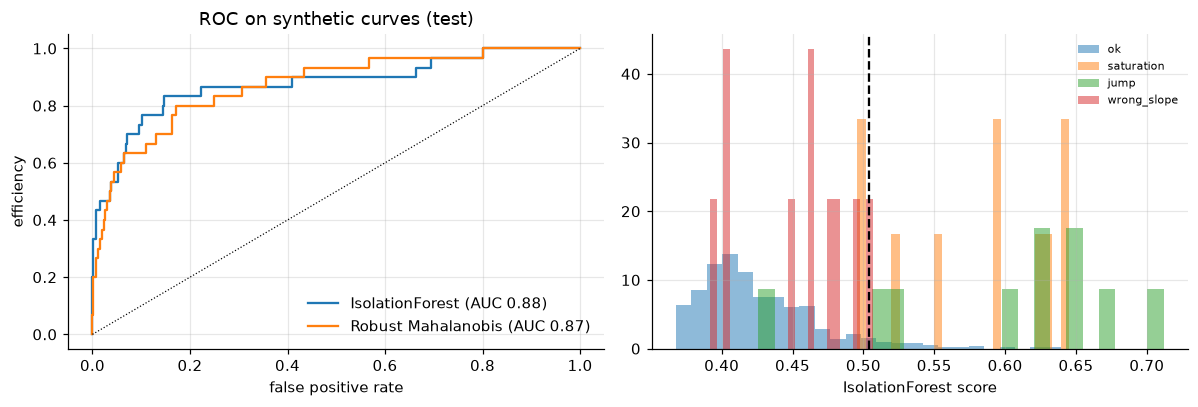

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for det in DET:
    s_ = -DET[det]().fit(Xs).score_samples(test[FEATS]); fp, tp, _ = roc_curve(is_bad, s_); ax[0].plot(fp, tp, label=f"{det} (AUC {auc_tab[det]:.2f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("efficiency"); ax[0].legend(); ax[0].set_title("ROC on synthetic curves (test)")
for d in ["ok"] + DEFECTS:
    m = (test.defect == d).to_numpy()
    if m.sum(): ax[1].hist(s_iso_test[m], bins=25, alpha=.5, density=True, label=d)
ax[1].axvline(thr_syn["IsolationForest"], c="k", ls="--"); ax[1].set_xlabel("IsolationForest score"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Most anomalous real curves

Here the detector is trained on the **real curves** (5-fold CV: the evaluated curve is not in the training set), with the threshold at the 95th percentile of the real scores: ~5% flagged by construction. Training on real data avoids the *domain gap* between synthetic and real data, but it also means that its efficiency can only be measured with the synthetic set (section 2). The top ones are to be **inspected by hand** in the plots of `afm_output/fit_plots/` (notebook 02); none is excluded.

In [5]:
real_s = real.loc[Xr.index, ["file_name", "group", "A_nN_per_um_3over2", "fit_r2", "snr", "jump_score", "sat_fraction"]].copy()
cv_iso, cv_maha = cv_scores(Xr, "IsolationForest"), cv_scores(Xr, "Robust Mahalanobis")
thr_iso, thr_maha = np.quantile(cv_iso, .95), np.quantile(cv_maha, .95)
real_s["score_iso"] = cv_iso; real_s["score_maha"] = cv_maha
real_s["flag_iso"] = real_s.score_iso > thr_iso; real_s["flag_maha"] = real_s.score_maha > thr_maha
real_s["group"] = real_s.group.map(T.short_group)
print("IF flags:", int(real_s.flag_iso.sum()), " Mahalanobis flags:", int(real_s.flag_maha.sum()), " both:", int((real_s.flag_iso & real_s.flag_maha).sum()),
      " | by construction ~5% =", int(.05 * len(real_s)))
real_s.to_csv(T.RESULTS_DIR / "05_real_anomaly_scores.csv", index=False)
summary["real_flagged_both"] = real_s[real_s.flag_iso & real_s.flag_maha].file_name.tolist()
real_s.sort_values("score_iso", ascending=False).head(10).round(3)

IF flags: 13  Mahalanobis flags: 13  both: 8  | by construction ~5% = 12


,file_name,group,A_nN_per_um_3over2,fit_r2,snr,jump_score,sat_fraction,score_iso,score_maha,flag_iso,flag_maha
235,nucleo-0066.jpk-force,T47DR nucleo,5.114,0.991,78.016,0.525,0.000,0.642,382.786,True,True
8,cito-0013.jpk-force,MCF7R cito,0.949,0.924,31.873,0.334,0.000,0.631,237.231,True,True
216,nucleo-0046.jpk-force,T47DR nucleo,0.456,0.995,90.326,0.162,0.001,0.612,259.810,True,True
220,nucleo-0050.jpk-force,T47DR nucleo,4.477,0.992,80.378,0.448,0.000,0.603,2070.150,True,True
234,nucleo-0065.jpk-force,T47DR nucleo,0.235,0.992,79.208,0.171,0.000,0.588,754.041,True,True
51,cito-0082.jpk-force,MCF7R cito,1.700,0.948,36.060,0.238,0.000,0.558,1103.432,True,True
80,nucleo-0034.jpk-force,MCF7R nucleo,0.319,0.994,88.172,0.168,0.000,0.536,987.294,True,True
9,cito-0014.jpk-force,MCF7R cito,0.577,0.934,37.617,0.307,0.000,0.519,141.761,True,False
185,nucleo-0013.jpk-force,T47DR nucleo,0.997,0.994,85.425,0.195,0.000,0.505,91.608,True,False
18,cito-0031.jpk-force,MCF7R cito,1.150,0.957,52.172,0.227,0.000,0.505,135.903,True,False


## 4. Classification: cytoplasm vs nucleus

For each line, a classifier predicts the region from the **mechanical and adhesion** features ($\log A$, maximum indentation, adhesion, work of adhesion; the baseline slope is not included to avoid session artifacts). Validation: stratified 5-fold repeated 5 times; AUC with spread from the repetitions; label **permutation test** for the chance level; calibration and Brier score.

In [6]:
MECH = ["logA", "max_indentation_um", "adhesion_nN", "adhesion_work_nN_um"]
data = real.dropna(subset=MECH).copy(); data["y"] = (data.region == "nucleo").astype(int)
models = {"logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "random forest": RandomForestClassifier(300, min_samples_leaf=3, random_state=SEED),
          "gradient boosting": GradientBoostingClassifier(random_state=SEED)}

def cv_auc(model, X, y, n_rep=5):
    aucs, proba = [], np.zeros(len(y))
    for r in range(n_rep):
        p = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r), method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(y, p)); proba += p / n_rep
    return np.mean(aucs), np.std(aucs), proba

rows, store = [], {}
for l in ["MCF7R", "T47DR"]:
    d = data[data.cell_line == l]
    for nm, m in models.items():
        a, s, p = cv_auc(m, d[MECH], d.y); store[(l, nm)] = (d.y.to_numpy(), p)
        rows.append(dict(line=l, model=nm, AUC=a, sd_repetitions=s, brier=brier_score_loss(d.y, p)))
cls = pd.DataFrame(rows); summary["classification"] = cls.round(4).to_dict("records"); cls.round(3)

,line,model,AUC,sd_repetitions,brier
0,MCF7R,logistic,0.951,0.002,0.091
1,MCF7R,random forest,0.929,0.005,0.105
2,MCF7R,gradient boosting,0.904,0.009,0.140
3,T47DR,logistic,0.626,0.013,0.230
4,T47DR,random forest,0.643,0.028,0.235
5,T47DR,gradient boosting,0.608,0.022,0.259


In [7]:
# permutation test (logistic, 200 permutations) and comparison with single features
rows = []
for l in ["MCF7R", "T47DR"]:
    d = data[data.cell_line == l]; a_obs = cls[(cls.line == l) & (cls.model == "logistic")].AUC.iloc[0]
    null = [cv_auc(models["logistic"], d[MECH], pd.Series(RNG.permutation(d.y.values), index=d.index), n_rep=1)[0] for _ in range(200)]
    only = {f: cv_auc(models["logistic"], d[[f]], d.y, n_rep=3)[0] for f in MECH}
    rows.append(dict(line=l, AUC=a_obs, AUC_null_mean=np.mean(null), p_perm=(np.sum(np.array(null) >= a_obs) + 1) / 201, **{f"only_{k}": v for k, v in only.items()}))
perm = pd.DataFrame(rows).set_index("line"); summary["permutation"] = perm.round(4).to_dict("index"); perm.round(3)

,AUC,AUC_null_mean,p_perm,only_logA,only_max_indentation_um,only_adhesion_nN,only_adhesion_work_nN_um
line,,,,,,,
MCF7R,0.951,0.467,0.005,0.906,0.939,0.740,0.747
T47DR,0.626,0.484,0.025,0.637,0.644,0.585,0.601


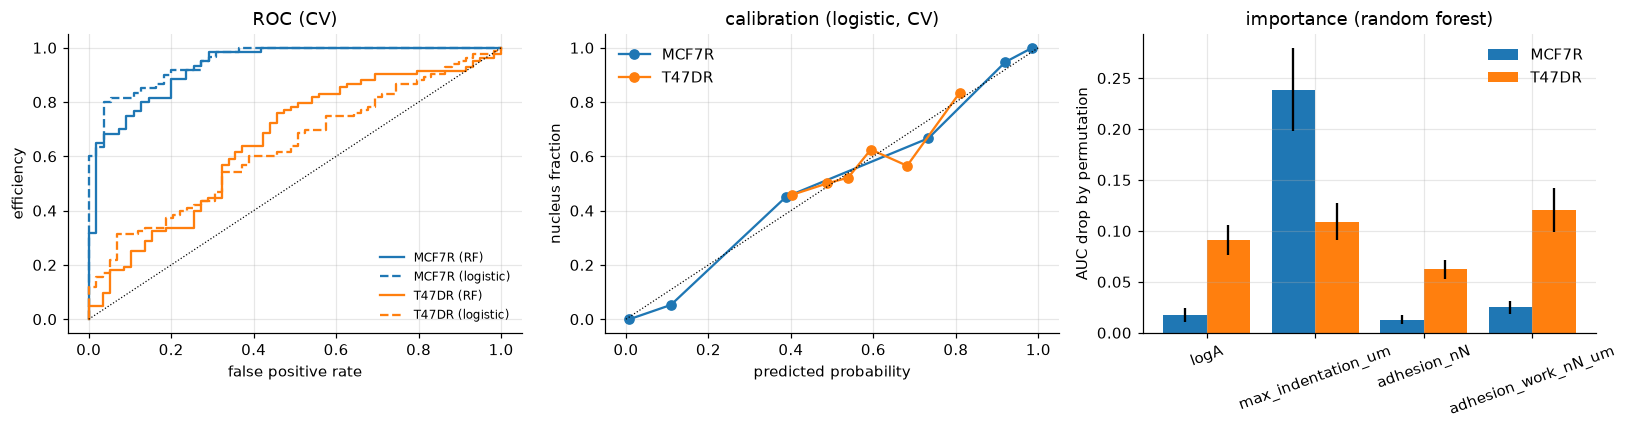

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for l, c in zip(["MCF7R", "T47DR"], ["C0", "C1"]):
    y, p = store[(l, "random forest")]; fp, tp, _ = roc_curve(y, p); ax[0].plot(fp, tp, c, label=f"{l} (RF)")
    y, p = store[(l, "logistic")]; fp, tp, _ = roc_curve(y, p); ax[0].plot(fp, tp, c + "--", label=f"{l} (logistic)")
    fr, mp = calibration_curve(y, p, n_bins=6, strategy="quantile"); ax[1].plot(mp, fr, "o-", color=c, label=l)
    d = data[data.cell_line == l]; m = models["random forest"].fit(d[MECH], d.y)
    imp = permutation_importance(m, d[MECH], d.y, n_repeats=30, random_state=SEED, scoring="roc_auc")
    ax[2].bar(np.arange(4) + (.4 if l == "T47DR" else 0), imp.importances_mean, .4, yerr=imp.importances_std, color=c, label=l)
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("efficiency"); ax[0].legend(fontsize=8); ax[0].set_title("ROC (CV)")
ax[1].plot([0, 1], [0, 1], "k:", lw=.8); ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("nucleus fraction"); ax[1].set_title("calibration (logistic, CV)"); ax[1].legend()
ax[2].set_xticks(np.arange(4) + .2, MECH, rotation=20); ax[2].set_ylabel("AUC drop by permutation"); ax[2].set_title("importance (random forest)"); ax[2].legend()
plt.tight_layout(); plt.show()

### Transfer between lines

If the «nucleus mechanical signature» were universal, a classifier trained on one line should work on the other. (With the caveat on the session: a different absolute scale of $A$ between sessions can degrade the transfer even if the phenomenon exists.)

In [9]:
rows = []
for a, b in [("MCF7R", "T47DR"), ("T47DR", "MCF7R")]:
    da, db = data[data.cell_line == a], data[data.cell_line == b]
    for nm in ["logistic", "random forest"]:
        m = models[nm].fit(da[MECH], da.y); p = m.predict_proba(db[MECH])[:, 1]
        # version with logA centred per line (removes the scale difference between sessions)
        da_c, db_c = da.copy(), db.copy(); da_c["logA"] -= da.logA.mean(); db_c["logA"] -= db.logA.mean()
        m2 = models[nm].fit(da_c[MECH], da_c.y); p2 = m2.predict_proba(db_c[MECH])[:, 1]
        rows.append(dict(train=a, test=b, model=nm, AUC=roc_auc_score(db.y, p), AUC_logA_centred=roc_auc_score(db.y, p2)))
transfer = pd.DataFrame(rows); summary["transfer"] = transfer.round(4).to_dict("records"); transfer.round(3)

,train,test,model,AUC,AUC_logA_centred
0,MCF7R,T47DR,logistic,0.658,0.658
1,MCF7R,T47DR,random forest,0.678,0.667
2,T47DR,MCF7R,logistic,0.955,0.955
3,T47DR,MCF7R,random forest,0.835,0.816


## 5. Bimodality of $\log A$: mixture models

The posterior predictive check of notebook 04 flagged an asymmetry not reproduced by the Gaussian model in the *nucleus* groups. For each group we compare 1 against 2 Gaussian components (BIC, and likelihood-ratio test with **parametric bootstrap**, because Wilks' distribution does not hold for mixtures).

In [10]:
def gmm_fit(x, k, seed=0): return GaussianMixture(k, n_init=5, random_state=seed).fit(x.reshape(-1, 1))
rows = []
for g in T.GROUP_ORDER:
    x = real[real.group == g].logA.to_numpy(); g1, g2 = gmm_fit(x, 1), gmm_fit(x, 2); q_obs = 2 * (g2.score(x.reshape(-1, 1)) - g1.score(x.reshape(-1, 1))) * len(x)
    null = []
    for b in range(200):
        xb = RNG.normal(x.mean(), x.std(), len(x)); a1, a2 = gmm_fit(xb, 1, b), gmm_fit(xb, 2, b); null.append(2 * (a2.score(xb.reshape(-1, 1)) - a1.score(xb.reshape(-1, 1))) * len(xb))
    rows.append(dict(group=T.short_group(g), n=len(x), dBIC_2_vs_1=g2.bic(x.reshape(-1, 1)) - g1.bic(x.reshape(-1, 1)), q_LRT=q_obs,
                     p_bootstrap=(np.sum(np.array(null) >= q_obs) + 1) / 201, weights=np.round(g2.weights_, 2).tolist(), means=np.round(g2.means_.ravel(), 2).tolist(),
                     sd=np.round(np.sqrt(g2.covariances_.ravel()), 2).tolist()))
mix = pd.DataFrame(rows).set_index("group"); summary["mixture"] = mix.to_dict("index"); mix.round(3)

,n,dBIC_2_vs_1,q_LRT,p_bootstrap,weights,means,sd
group,,,,,,,
MCF7R cito,55,9.806,2.216,0.403,"[0.52, 0.48]","[-0.28, 0.42]","[0.35, 0.28]"
MCF7R nucleo,60,5.847,6.436,0.075,"[0.29, 0.71]","[-0.36, -0.92]","[0.23, 0.2]"
T47DR cito,59,6.002,6.230,0.095,"[0.47, 0.53]","[-0.55, 0.29]","[0.27, 0.29]"
T47DR nucleo,83,-0.498,13.755,0.010,"[0.71, 0.29]","[-0.64, 0.35]","[0.37, 0.6]"


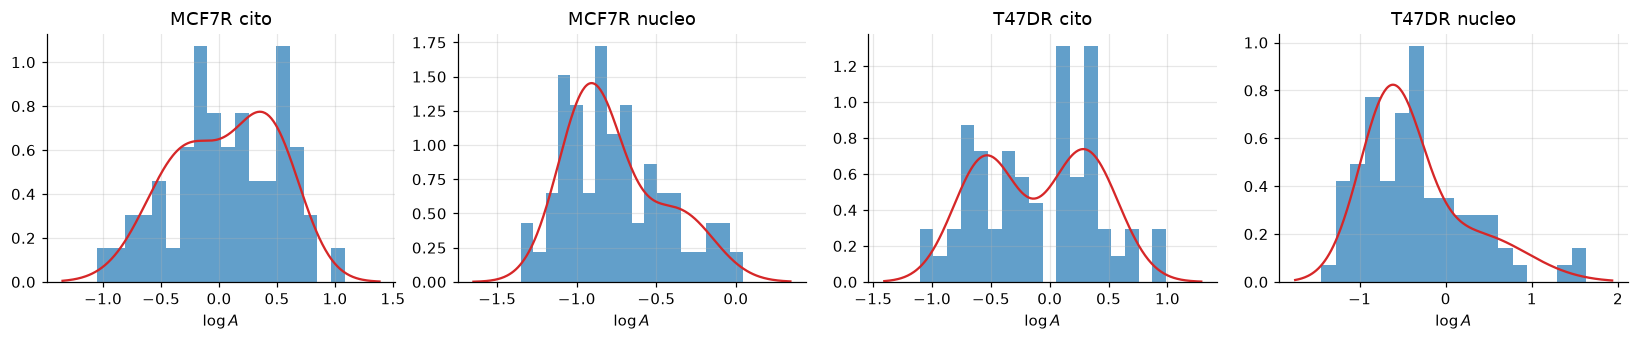

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, g in zip(ax, T.GROUP_ORDER):
    x = real[real.group == g].logA.to_numpy(); a.hist(x, bins=18, density=True, alpha=.7); t = np.linspace(x.min() - .3, x.max() + .3, 300)
    g2 = gmm_fit(x, 2); a.plot(t, np.exp(g2.score_samples(t.reshape(-1, 1))), "C3"); a.set_title(T.short_group(g)); a.set_xlabel(r"$\log A$")
plt.tight_layout(); plt.show()
json.dump(summary, open(T.RESULTS_DIR / "05_summary.json", "w"), indent=1, default=float)

## Interpretation and limits

- **Anomaly detection.** `no_contact` and `huge_noise` are already caught by the failure of the fit; `jump` and `saturation` are detected in 60–90% of the cases at ~5% false positives; `wrong_slope` remains difficult (≈10–30%): the free contact point absorbs most of the distortion, and the estimated exponent (`exponent_hat`) helps only in part. With only 10 defects per type the binomial uncertainty on each efficiency is about ±15%. The efficiency holds for this generator (Hertz plus model mismatch plus ideal defects): it is optimistic with respect to real defects.
- **Flagged real curves.** The curves flagged by both detectors (≈5% by construction) are only candidates for visual inspection; none has been excluded from the statistical analysis.
- **Classification.** The region is well predicted in MCF7R (AUC ≈ 0.95; maximum indentation and $\log A$ carry almost all the information) and weakly in T47DR (AUC ≈ 0.63, but significant with the permutation test): consistent with the effects of notebooks 03–04. A model trained on one line transfers to the other with an AUC similar to the in-line one (centring $\log A$ per line changes little): the «softer nucleus» sign is qualitatively shared, but the size of the effect is not.
- **Mixture.** The parametric bootstrap favours two components only for T47DR nucleus ($p\approx0.01$; secondary component at high $\log A$ and broad): it is the source of the asymmetry seen in the posterior predictive check of notebook 04. In the other groups the mixture is not significant. A comparison of means alone therefore summarizes T47DR nucleus poorly.
- **Confounding.** Pseudo-replication (curves of the same cell) and line≡session hold here too, and the CV AUC of curves of the same cell is optimistic.

## Output produced

```text
results/05_summary.json              detector efficiency, classification, permutation, transfer, mixtures
results/05_real_anomaly_scores.csv   anomaly score of every real curve (diagnostic)
```

With this notebook the analysis pipeline is complete: 01 reader+QC → 02 contact+fit → 03 frequentist → 04 Bayesian → 05 ML.